# Risk Alert Classifier

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

## Part A: Conceptual Understanding

**1. What is Logistic Regression and why is it suitable for classification?**

Logistic Regression is a supervised algorithm that models the probability of the positive class by passing a linear combination of the features through the sigmoid function: P(y=1 | x) = 1 / (1 + e^-(b0 + b1x1 + ... + bnxn)). The probability is converted to a class using a threshold (default 0.5). It suits classification because its output is always between 0 and 1, it is fast, and its coefficients are interpretable as changes in log-odds, which makes it a strong baseline for a binary target such as Risk Status.

**2. Classification performance metrics, and why accuracy alone is insufficient**

Classification metrics (confusion matrix, accuracy, precision, recall, F1-score, AUC-ROC) compare predicted classes with actual classes. Accuracy = (TP + TN) / total and ignores *which* mistakes are made. In this dataset only about 12% of customers are high risk, so a model that labels everyone "Low Risk" is about 88% accurate while catching zero risky customers. Class-wise metrics such as recall and precision are needed to expose this.

**3. Type-I and Type-II Error in risk prediction**

- **Type-I Error (False Positive):** a genuinely low-risk customer is flagged as high risk. Cost: unnecessary review work, blocked transactions, an annoyed customer.
- **Type-II Error (False Negative):** a genuinely high-risk customer is predicted as low risk. Cost: an undetected default or fraud loss. For an early-warning system this is the more expensive error.

**4. Precision, Recall, F1-Score, TPR and FPR**

- **Precision** = TP / (TP + FP): of all customers flagged high risk, how many really are.
- **Recall = TPR (Sensitivity)** = TP / (TP + FN): of all truly high-risk customers, how many were caught.
- **F1-Score** = 2 x (Precision x Recall) / (Precision + Recall): harmonic mean, balances the two.
- **FPR** = FP / (FP + TN): share of low-risk customers wrongly flagged.

**5. What is AUC-ROC and how does it help in evaluating classifiers?**

The ROC curve plots TPR against FPR at every possible classification threshold; AUC is the area under that curve. AUC = 0.5 means random guessing and 1.0 means perfect separation; it can be read as the probability that a randomly chosen high-risk customer gets a higher score than a randomly chosen low-risk one. It is threshold-independent, so it lets us compare models fairly before choosing an operating threshold.

**6. Why does imbalanced data create problems?**

A model minimises overall error, so with few minority samples it can reach high accuracy by favouring the majority class, leaving recall for the minority (high-risk) class low. The decision boundary is pulled towards the minority class and accuracy becomes misleading. Remedies: resampling (under-sampling, over-sampling, SMOTE, ADASYN), class weights, threshold tuning, and judging models with recall, F1 and AUC instead of accuracy.


## Part B: Dataset Understanding & Preparation

In [2]:
df = pd.read_csv("dataset/Risk_Alert_Classifier_Dataset_4600.csv")

In [3]:
df.head()

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [4]:
df.shape

(4600, 19)

In [5]:
print("Target Class Distribution : ")
print(df['risk_status'].value_counts())

Target Class Distribution : 
risk_status
0    4043
1     557
Name: count, dtype: int64


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

In [7]:
df.isna().sum()

,0
customer_id,0
age,140
gender,0
region,102
employment_type,144
annual_income_inr,166
credit_score,216
credit_utilization_ratio,147
missed_payments_12m,0
avg_late_payment_days,0


In [8]:
df['last_transaction_date'] = pd.to_datetime(df['last_transaction_date'])

In [9]:
ref_date = df['last_transaction_date'].max() + pd.Timedelta(days=1)
df['last_txn_days_ago'] = (ref_date - df['last_transaction_date']).dt.days

In [10]:
df.drop(columns=['customer_id', 'last_transaction_date'], axis = 1, inplace=True)

In [11]:
df.head()

,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,debt_balance_inr,risk_status,last_txn_days_ago
0,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,87273,0,67
1,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,20600,0,8
2,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,47565,0,67
3,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,43803,1,60
4,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,12008,0,37


### Categorical Column Encoding

In [12]:
print("Gender Value counts : ", df['gender'].value_counts())
print("\n Region Values counts : ", df['region'].value_counts())
print("\n employment type value counts : ", df['employment_type'].value_counts())

Gender Value counts :  gender
Male      2358
Female    2199
Other       43
Name: count, dtype: int64

 Region Values counts :  region
South      1057
North       989
West        900
East        818
Central     734
Name: count, dtype: int64

 employment type value counts :  employment_type
Salaried         2354
Self-Employed    1133
Student           393
Unemployed        355
Retired           221
Name: count, dtype: int64


In [13]:
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1, 'Other': 2})
df['region'] = df['region'].map({'Central': 0, 'East': 1, 'North': 2, 'South': 3, 'West': 4})
df['employment_type'] = df['employment_type'].map({'Retired': 0, 'Salaried': 1, 'Self-Employed': 2, 'Student': 3, 'Unemployed': 4})

categorical_columns = ['gender', 'region', 'employment_type']
df[categorical_columns].isna().sum()

,0
gender,0
region,102
employment_type,144


In [14]:
df[['gender', 'region', 'employment_type']].head()

,gender,region,employment_type
0,0,NaN,1.0
1,0,0.0,1.0
2,1,1.0,1.0
3,1,2.0,4.0
4,0,1.0,2.0


### Identify input features and target variable.


In [15]:
X = df.drop('risk_status', axis = 1)
y = df['risk_status']

### apply KNN Imputer for multivariate imputation

In [16]:
imputer = KNNImputer(n_neighbors=5)
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns = X.columns)

In [17]:
X_imputed.isna().sum()

,0
age,0
gender,0
region,0
employment_type,0
annual_income_inr,0
credit_score,0
credit_utilization_ratio,0
missed_payments_12m,0
avg_late_payment_days,0
monthly_transaction_count,0


In [18]:
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)

print("Training Set Shape :", X_train.shape)
print("Testing Set Shape  :", X_test.shape)

print("\nTraining Class Distribution :")
print(y_train.value_counts())

print("\nTesting Class Distribution :")
print(y_test.value_counts())

Training Set Shape : (3680, 17)
Testing Set Shape  : (920, 17)

Training Class Distribution :
risk_status
0    3247
1     433
Name: count, dtype: int64

Testing Class Distribution :
risk_status
0    796
1    124
Name: count, dtype: int64


In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Part C: Baseline Classification Model

### Logistic Regression

In [20]:
lr = LogisticRegression(random_state=50)
lr.fit(X_train_scaled, y_train)

LogisticRegression(random_state=50)

In [21]:
y_pred_lr = lr.predict(X_test_scaled)

In [22]:
cm = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix : \n", cm)

Confusion Matrix : 
 [[795   1]
 [  0 124]]


In [23]:
print("Accuracy : ", accuracy_score(y_test, y_pred_lr))
print("Precision : ", precision_score(y_test, y_pred_lr))
print("Recall : ", recall_score(y_test, y_pred_lr))
print("F1 Score : ", f1_score(y_test, y_pred_lr))

Accuracy :  0.9989130434782608
Precision :  0.992
Recall :  1.0
F1 Score :  0.9959839357429718


In [24]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       796
           1       0.99      1.00      1.00       124

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



In [25]:
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

print("True Positives (TP) : ", TP)
print("True Negatives (TN) : ", TN)
print("False Positives (FP) : ", FP)
print("False Negatives (FN) : ", FN)

True Positives (TP) :  124
True Negatives (TN) :  795
False Positives (FP) :  1
False Negatives (FN) :  0


## Part D: Handling Imbalanced Data

In [26]:
print("Class Distribution :", y_train.value_counts())

Class Distribution : risk_status
0    3247
1     433
Name: count, dtype: int64


### Under-Sampling

In [27]:
rus = RandomUnderSampler(random_state=50)
X_train_rus, y_train_rus = rus.fit_resample(X_train_scaled, y_train)

print("Class Distribution after Under-Sampling :", y_train_rus.value_counts())

Class Distribution after Under-Sampling : risk_status
0    433
1    433
Name: count, dtype: int64


In [28]:
lr_rus = LogisticRegression(random_state=50)
lr_rus.fit(X_train_rus, y_train_rus)
y_pred_lr_rus = lr_rus.predict(X_test_scaled)

### Over-Sampling

In [29]:
ros = RandomOverSampler(random_state=50)
X_train_ros, y_train_ros = ros.fit_resample(X_train_scaled, y_train)

print("Class Distribution after Over-Sampling :", y_train_ros.value_counts())

Class Distribution after Over-Sampling : risk_status
0    3247
1    3247
Name: count, dtype: int64


In [30]:
lr_ros = LogisticRegression(random_state=50)
lr_ros.fit(X_train_ros, y_train_ros)
y_pred_lr_ros = lr_ros.predict(X_test_scaled)

### SMOTE

In [31]:
smote = SMOTE(random_state=50)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Class Distribution after SMOTE :", y_train_smote.value_counts())

Class Distribution after SMOTE : risk_status
0    3247
1    3247
Name: count, dtype: int64


In [32]:
lr_smote = LogisticRegression(random_state=50)
lr_smote.fit(X_train_smote, y_train_smote)
y_pred_lr_smote = lr_smote.predict(X_test_scaled)

### ADASYN

In [33]:
adasyn = ADASYN(random_state=50)
X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train_scaled, y_train)

print("Class Distribution after ADASYN :", y_train_adasyn.value_counts())

Class Distribution after ADASYN : risk_status
0    3247
1    3238
Name: count, dtype: int64


In [34]:
lr_adasyn = LogisticRegression(random_state=50)
lr_adasyn.fit(X_train_adasyn, y_train_adasyn)
y_pred_lr_adasyn = lr_adasyn.predict(X_test_scaled)

### Compare Performance

In [35]:
sampling_result = {
    "Sampling Method" : ["Original", "Under-Sampling", "Over-Sampling", "SMOTE", "ADASYN"],
    "Recall" : [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr_rus),
        recall_score(y_test, y_pred_lr_ros),
        recall_score(y_test, y_pred_lr_smote),
        recall_score(y_test, y_pred_lr_adasyn)],
    "F1 Score" : [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr_rus),
        f1_score(y_test, y_pred_lr_ros),
        f1_score(y_test, y_pred_lr_smote),
        f1_score(y_test, y_pred_lr_adasyn)],
    "AUC-ROC" : [
        roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test, lr_rus.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test, lr_ros.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test, lr_smote.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test, lr_adasyn.predict_proba(X_test_scaled)[:, 1])
    ]
}

sampling_result_df = pd.DataFrame(sampling_result)
sampling_result_df

,Sampling Method,Recall,F1 Score,AUC-ROC
0,Original,1.0,0.995984,1.00000
1,Under-Sampling,1.0,0.972549,0.99997
2,Over-Sampling,1.0,0.972549,1.00000
3,SMOTE,1.0,0.984127,1.00000
4,ADASYN,1.0,0.961240,1.00000


## Part E: Tree-Based Classification Models

### Decision Tree Classifier

In [36]:
dt_model = DecisionTreeClassifier(random_state=50)
dt_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=50)

In [37]:
y_pred_dt_train = dt_model.predict(X_train_scaled)
y_pred_dt_test = dt_model.predict(X_test_scaled)

In [38]:
dt_train_accuracy = accuracy_score(y_train, y_pred_dt_train)
dt_test_accuracy = accuracy_score(y_test, y_pred_dt_test)

print("Decision Tree : ")
print("Train Accuracy :", dt_train_accuracy)
print("Test Accuracy :", dt_test_accuracy)
print("Difference : ", dt_train_accuracy - dt_test_accuracy)

Decision Tree : 
Train Accuracy : 1.0
Test Accuracy : 0.9619565217391305
Difference :  0.03804347826086951


In [39]:
if dt_train_accuracy == 1.0:
  print("Overfitting : model memorized the training data")
elif (dt_train_accuracy - dt_test_accuracy) > 0.05:
  print("Overfitting : model is not generalizing well to new data")
else:
  print("Good fit")

Overfitting : model memorized the training data


###  Random Forest Classifier

In [40]:
rf = RandomForestClassifier(n_estimators=100 ,random_state=50)
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=50)

In [41]:
y_pred_rf_train = rf.predict(X_train_scaled)
y_pred_rf_test = rf.predict(X_test_scaled)

In [42]:
rf_train_accuracy = accuracy_score(y_train, y_pred_rf_train)
rf_test_accuracy = accuracy_score(y_test, y_pred_rf_test)

In [43]:
print("Random Forest : ")
print("Train Accuracy :", rf_train_accuracy)
print("Test Accuracy :", rf_test_accuracy)
print("Difference : ", rf_train_accuracy - rf_test_accuracy)

Random Forest : 
Train Accuracy : 1.0
Test Accuracy : 0.9902173913043478
Difference :  0.009782608695652173


### Comparison

In [44]:
comparison = pd.DataFrame({
    "Model" : ["Decision Tree", "Random Forest"],
    "Train Accuracy" : [dt_train_accuracy, rf_train_accuracy],
    "Test Accuracy" : [dt_test_accuracy, rf_test_accuracy],
    "Recall" : [recall_score(y_test, y_pred_dt_test), recall_score(y_test, y_pred_rf_test)],
    "F1 Score" : [f1_score(y_test, y_pred_dt_test), f1_score(y_test, y_pred_rf_test)]
})
comparison

,Model,Train Accuracy,Test Accuracy,Recall,F1 Score
0,Decision Tree,1.0,0.961957,0.862903,0.859438
1,Random Forest,1.0,0.990217,0.951613,0.963265


## Part F: Hyperparameter Tuning

### Randomized SearchCV - Decision Tree

In [45]:
param_grid = {
    "max_depth" : [3, 5, 7, 10],
    "min_samples_split" : [2, 5, 10],
    "min_samples_leaf" : [1, 2, 4],
    "criterion" : ["gini", "entropy"]
}

randomized = RandomizedSearchCV(estimator=dt_model, param_distributions=param_grid, n_iter=20, cv=5, random_state=50, scoring="recall", n_jobs=-1)
randomized.fit(X_train_scaled, y_train)

best_params = randomized.best_params_
best_model = randomized.best_estimator_

print("Best Parameters :", best_params)

Best Parameters : {'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 7, 'criterion': 'entropy'}


### Randomized SearchCV - Random Forest

In [46]:
param_grid2 = {
    "n_estimators" : [50, 100, 150, 200],
    "max_depth" : [3, 5, 7, 10],
    "min_samples_split" : [2, 5, 10],
    "min_samples_leaf" : [1, 2, 4]
}

randomized2 = RandomizedSearchCV(estimator=rf, param_distributions=param_grid2, n_iter=20, cv=5, random_state=50,  scoring="recall", n_jobs=-1)
randomized2.fit(X_train_scaled, y_train)

best_params = randomized2.best_params_
best_model = randomized2.best_estimator_

print("Best Parameters :", best_params)

Best Parameters : {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 10}


### Grid SearchCV

In [47]:
rf_grid_params = {
    "n_estimators" : [50, 100, 150, 200],
    "max_depth" : [3, 5, 7, 10],
    "min_samples_split" : [2, 5]
}

rf_grid = GridSearchCV(estimator=rf, param_grid=rf_grid_params, cv=5, n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

print("Best Grid rf parameters : ", rf_grid.best_params_)

Best Grid rf parameters :  {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}


In [48]:
best_rf_model = rf_grid.best_estimator_
best_dt = randomized.best_estimator_

In [49]:
best_rf_pred = best_rf_model.predict(X_test_scaled)
best_dt_pred = best_dt.predict(X_test_scaled)

In [50]:
dt_test_accuracy_tuned = accuracy_score(y_test, best_dt_pred)
rf_test_accuracy_tuned = accuracy_score(y_test,best_rf_pred)

### Comparison

In [51]:
tuning_comparison = pd.DataFrame({
    "Model" : ["Decision Tree(Untuned)", "Decision Tree(Tuned)", "Random Forest(Ununed)", "Random Forest(Tuned)"],
    "Accuracy" : [dt_test_accuracy, dt_test_accuracy_tuned  , rf_test_accuracy, rf_test_accuracy_tuned ],
    "Recall" : [recall_score(y_test, y_pred_dt_test), recall_score(y_test, best_dt_pred), recall_score(y_test, y_pred_rf_test), recall_score(y_test, best_rf_pred)],
    "F1 Score" : [f1_score(y_test, y_pred_dt_test), f1_score(y_test, best_dt_pred), f1_score(y_test, y_pred_rf_test), f1_score(y_test, best_rf_pred)]
    })
tuning_comparison

,Model,Accuracy,Recall,F1 Score
0,Decision Tree(Untuned),0.961957,0.862903,0.859438
1,Decision Tree(Tuned),0.978261,0.927419,0.920000
2,Random Forest(Ununed),0.990217,0.951613,0.963265
3,Random Forest(Tuned),0.990217,0.935484,0.962656


## Part G: Model Evaluation & ROC Analysis

### ROC Curve

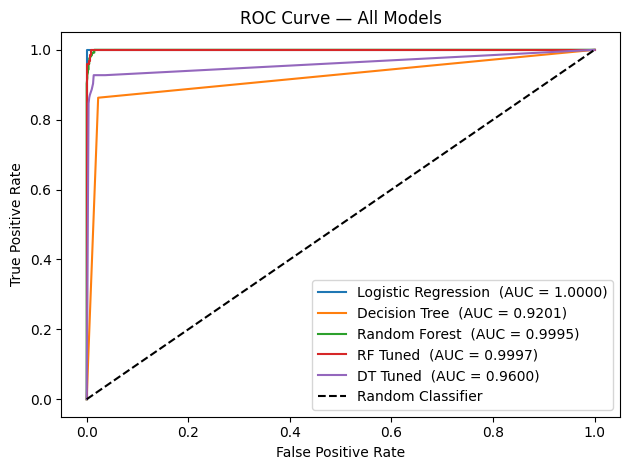

ROC Curve saved as roc_curve.png


In [52]:
models_roc = {
    'Logistic Regression' : lr,
    'Decision Tree' : dt_model,
    'Random Forest' : rf,
    'RF Tuned' : best_rf_model,
    'DT Tuned' : best_dt
}

for name, model in models_roc.items():
    prob = model.predict_proba(X_test_scaled)[:,1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name}  (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — All Models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=100)
plt.show()
print("ROC Curve saved as roc_curve.png")

### AUC - ROC Score

In [53]:
auc_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'RF Tuned', 'DT Tuned'],
    'AUC-ROC': [roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, dt_model.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, rf.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, best_rf_model.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, best_dt.predict_proba(X_test_scaled)[:, 1])]
})

auc_results.sort_values(by='AUC-ROC', ascending=False)

,Model,AUC-ROC
0,Logistic Regression,1.000000
3,RF Tuned,0.999676
2,Random Forest,0.999534
4,DT Tuned,0.960042
1,Decision Tree,0.920145


###  Select Best Final Model

In [54]:
final_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'RF Tuned', 'DT Tuned'],
    'Accuracy': [accuracy_score(y_test, lr.predict(X_test_scaled)),
                 accuracy_score(y_test, dt_model.predict(X_test_scaled)),
                 accuracy_score(y_test, rf.predict(X_test_scaled)),
                 accuracy_score(y_test, best_rf_model.predict(X_test_scaled)),
                 accuracy_score(y_test, best_dt.predict(X_test_scaled))],

    'Recall': [recall_score(y_test, lr.predict(X_test_scaled)),
               recall_score(y_test, dt_model.predict(X_test_scaled)),
               recall_score(y_test, rf.predict(X_test_scaled)),
               recall_score(y_test, best_rf_model.predict(X_test_scaled)),
               recall_score(y_test, best_dt.predict(X_test_scaled))],

    'F1 Score': [f1_score(y_test, lr.predict(X_test_scaled)),
                 f1_score(y_test, dt_model.predict(X_test_scaled)),
                 f1_score(y_test, rf.predict(X_test_scaled)),
                 f1_score(y_test, best_rf_model.predict(X_test_scaled)),
                 f1_score(y_test, best_dt.predict(X_test_scaled))],

    'AUC-ROC': [roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, dt_model.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, rf.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, best_rf_model.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, best_dt.predict_proba(X_test_scaled)[:, 1])]

})
print("Final Comparison : ")
print(final_comparison.sort_values('Recall', ascending=False))

Final Comparison : 
                 Model  Accuracy    Recall  F1 Score   AUC-ROC
0  Logistic Regression  0.998913  1.000000  0.995984  1.000000
2        Random Forest  0.990217  0.951613  0.963265  0.999534
3             RF Tuned  0.990217  0.935484  0.962656  0.999676
4             DT Tuned  0.978261  0.927419  0.920000  0.960042
1        Decision Tree  0.961957  0.862903  0.859438  0.920145


## Part H: Final Analysis & Reporting



### 1. Best Classification Model and Justification

In [55]:
models = {'Logistic Regression': lr, 'Decision Tree': dt_model, 'Random Forest': rf,
          'RF Tuned': best_rf_model, 'DT Tuned': best_dt}

rows = []
for name, m in models.items():
    pred = m.predict(X_test_scaled)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1 Score': f1_score(y_test, pred),
                 'AUC-ROC': roc_auc_score(y_test, m.predict_proba(X_test_scaled)[:, 1]),
                 'False Negatives': fn, 'False Positives': fp})

results = pd.DataFrame(rows).sort_values(['False Negatives', 'False Positives', 'AUC-ROC'],
                                         ascending=[True, True, False]).reset_index(drop=True)
best = results.iloc[0]
best_model_name = best['Model']
best_model = models[best_model_name]

display(results.round(4))
print("BEST MODEL:", best_model_name)
print(f"Recall = {best['Recall']:.4f} | F1 = {best['F1 Score']:.4f} | AUC-ROC = {best['AUC-ROC']:.4f}")
print("Why: bank want to catch risky customers, so fewest False Negatives win.")

,Model,Accuracy,Recall,F1 Score,AUC-ROC,False Negatives,False Positives
0,Logistic Regression,0.9989,1.0000,0.9960,1.0000,0,1
1,Random Forest,0.9902,0.9516,0.9633,0.9995,6,3
2,RF Tuned,0.9902,0.9355,0.9627,0.9997,8,1
3,DT Tuned,0.9783,0.9274,0.9200,0.9600,9,11
4,Decision Tree,0.9620,0.8629,0.8594,0.9201,17,18


BEST MODEL: Logistic Regression
Recall = 1.0000 | F1 = 0.9960 | AUC-ROC = 1.0000
Why: bank want to catch risky customers, so fewest False Negatives win.


### 2. Impact of Imbalance Handling Techniques

,Sampling Method,Recall,F1 Score,AUC-ROC
0,Original,1.0,0.9960,1.0
1,Under-Sampling,1.0,0.9725,1.0
2,Over-Sampling,1.0,0.9725,1.0
3,SMOTE,1.0,0.9841,1.0
4,ADASYN,1.0,0.9612,1.0


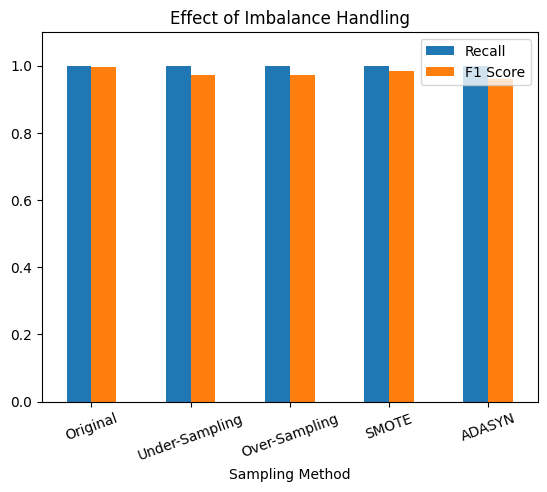

Original recall: 1.0
Best F1 method : Original
Read: recall same but F1 lower = balancing only added False Positives.


In [56]:
display(sampling_result_df.round(4))

sampling_result_df.set_index('Sampling Method')[['Recall', 'F1 Score']].plot(
    kind='bar', ylim=(0, 1.1), rot=20, title='Effect of Imbalance Handling')
plt.savefig('sampling_result.png', dpi=100)
plt.show()

print("Original recall:", round(sampling_result_df['Recall'].iloc[0], 4))
print("Best F1 method :", sampling_result_df.loc[sampling_result_df['F1 Score'].idxmax(), 'Sampling Method'])
print("Read: recall same but F1 lower = balancing only added False Positives.")

### 3. Comparison of Performance Metrics

,Model,Accuracy,Recall,F1 Score,AUC-ROC,False Negatives,False Positives
0,Logistic Regression,0.9989,1.0000,0.9960,1.0000,0,1
1,Random Forest,0.9902,0.9516,0.9633,0.9995,6,3
2,RF Tuned,0.9902,0.9355,0.9627,0.9997,8,1
3,DT Tuned,0.9783,0.9274,0.9200,0.9600,9,11
4,Decision Tree,0.9620,0.8629,0.8594,0.9201,17,18


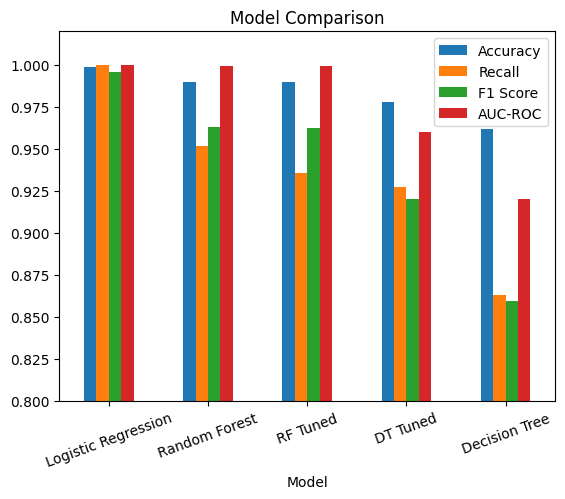

Best Model: Logistic Regression
Read: single tree overfit more. Random Forest generalise better. Check Recall, not only Accuracy.


In [57]:
display(results.round(4))

results.set_index('Model')[['Accuracy', 'Recall', 'F1 Score', 'AUC-ROC']].plot(
    kind='bar', ylim=(0.8, 1.02), rot=20, title='Model Comparison')
plt.savefig('model_comparison.png', dpi=100)
plt.show()
print("Best Model:", best_model_name)

print("Read: single tree overfit more. Random Forest generalise better. Check Recall, not only Accuracy.")

### 4. Business Interpretation of False Positives and False Negatives

In [58]:
tn, fp, fn, tp = confusion_matrix(y_test, best_model.predict(X_test_scaled)).ravel()

print("False Negatives:", fn, "-> risky customer missed -> default/fraud loss. COSTLY.")
print("False Positives:", fp, "-> safe customer flagged -> extra review work. CHEAPER.")
print("Bank accept more False Positives to get fewer False Negatives.")

False Negatives: 0 -> risky customer missed -> default/fraud loss. COSTLY.
False Positives: 1 -> safe customer flagged -> extra review work. CHEAPER.
Bank accept more False Positives to get fewer False Negatives.


### Final Conclusion and Recommendations
- Use recall, F1, AUC-ROC and confusion matrix. Accuracy alone mislead on imbalanced data.
- Deploy best model as early-warning score. Send flagged customers to manual review.
- Set alert threshold from real cost of missed defaulter vs extra review, not default 0.5.
- Monitor late-payment days, missed payments, credit utilisation, credit score first.
- Limitation: dataset synthetic, test set has few high-risk customers, cost figures assumed.